<a href="https://colab.research.google.com/github/ElBaron-27/UACJ_Ruben/blob/main/Pr%C3%A1cticaRegresionDatosCategoricos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

** Regresión lineal con datos categóricos: Costos, Localidades y Salarios**

📌 Objetivos de la Práctica:
Al finalizar esta práctica, los estudiantes serán capaces de:

- Codificar variables categóricas usando one-hot encoding con K-1 para problemas de regresión
- Realizar AED
- Construir un modelo de regresión con variables dummy
- Interpretar los resultados de los coeficientes
- Analizar los resultados de los errores residuales
- Calcular el desempeño del modelo de regresión.

Problema: Se podría argumentar que el salario está relacionado con el costo de la educación. Por lo tanto, para analizar este argumentos veremos qué sucede cuando usamos las variables independientes cost y location.

# 1. Carga de datos

Carga el conjunto de datos college.csv, que está en campus virtual, en un dataframe. Elige de este conjunto las columnas salary (variable dependiente), cost(variable independiente - numérica) y location (variable independiente categórica).

Realiza lo siguiente:

*   Convierte si es necesario la variable location a tipo de dato categórico
*   Usa la instrucción describe() en las variables salary y cost
* Cuenta la cantidad de datos que hay por categoría en location
* Convierte la variable location usando one-hot encoding



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# 1. Cargar el dataset de advertising
df = pd.read_csv('/content/drive/MyDrive/MIAAD UACJ/college.csv')

print(df.head())
# Descripción estadística del dataset
print("\nDescripción estadística de variables:")
print(df[["salary", "cost"]].describe())

# Comprobamos si hay valores nulos
print("\nComprobando valores nulos:")
print(df.isnull().sum())

df["location"] = df["location"].astype("category")

df["location"].dtype

df["location"].value_counts()

df_encoded = pd.get_dummies(
    df[["salary", "cost", "location"]],
    columns=["location"],
    drop_first=True,
    dtype=int
)

print(df["location"].value_counts())
print(df_encoded.head())

   id                                         name  salary    cost   public  \
0   1  Massachusetts Institute of Technology (MIT)  119000  189300  Private   
1   2                           Harvard University  121000  189600  Private   
2   3                            Dartmouth College  123000  188400  Private   
3   4                         Princeton University  123000  188700  Private   
4   5                              Yale University  110000  194200  Private   

  location  
0       NE  
1       NE  
2       NE  
3       NE  
4       NE  

Descripción estadística de variables:
              salary           cost
count      85.000000      85.000000
mean    95898.823529  142434.470588
std     11937.121912   53913.064578
min     74900.000000   18260.000000
25%     87100.000000   84670.000000
50%     93200.000000  169200.000000
75%    105000.000000  188700.000000
max    123000.000000  227300.000000

Comprobando valores nulos:
id          0
name        0
salary      0
cost        0


# 2. Análisis Exploratorio de los Datos

Realiza un análisis exploratorio de los datos y discute lo que observas en cada gráfica.


*   Crea un histograma de la columna salary. Discute lo que observas
* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas
* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas




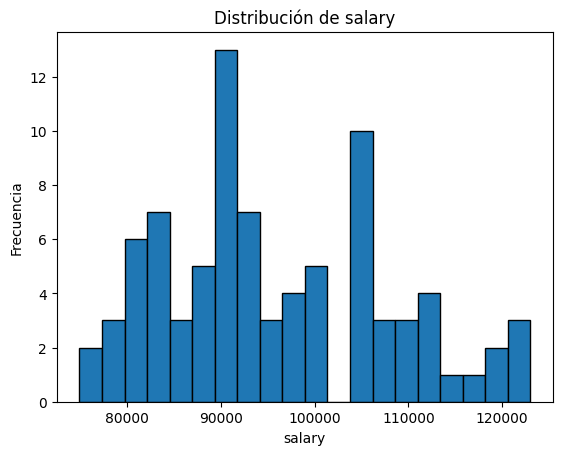

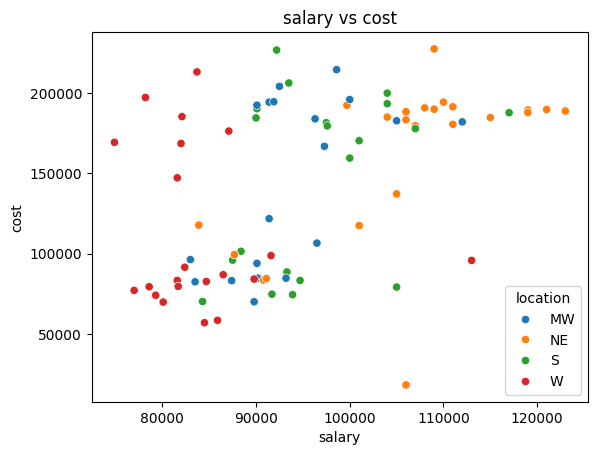

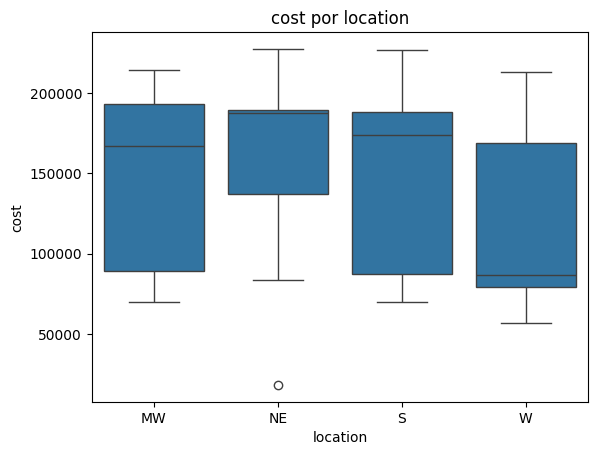

In [3]:
plt.hist(df["salary"], bins=20, edgecolor="black")
plt.title("Distribución de salary")
plt.xlabel("salary")
plt.ylabel("Frecuencia")
plt.show()

sns.scatterplot(data=df, x="salary", y="cost", hue="location")
plt.title("salary vs cost")
plt.show()

sns.boxplot(data=df, x="location", y="cost")
plt.title("cost por location")
plt.show()

*   Crea un histograma de la columna salary. Discute lo que observas

**Respuesta: El histograma muestra que los salarios se distribuyen aproximadamente entre 75,000 y 123,000, con una mayor concentración de observaciones entre 80,000 y 110,000. Se observan varias concentraciones de frecuencia, especialmente alrededor de 90,000 y 105,000, por lo que la distribución no presenta una forma normal claramente definida. Esto sugiere que los salarios de las instituciones analizadas no se concentran uniformemente alrededor de la media y que existen diferencias importantes entre las observaciones.**

* Crea un diagrama de dispersión de salary vs cost, considerando lo siguiente: para cada punto elegirás un color que represente la localidad en la que está el salario y el costo de la educación. Por lo tanto el diagrama de dispersión debería tener puntos en 4 colores distintos. Discute lo que observas

**Respuesta: El diagrama de dispersión permite observar una relación positiva general entre el costo de la educación y el salario. Esto significa que, en términos generales, las instituciones con mayores costos tienden a estar asociadas con salarios más elevados. Sin embargo, la relación no es completamente lineal, ya que existen instituciones con costos similares y salarios diferentes. Al distinguir las observaciones por ubicación geográfica, se aprecia que la región NE concentra varias instituciones con costos y salarios elevados, mientras que la región W presenta una mayor concentración de salarios bajos. Por lo tanto, la ubicación geográfica parece ser una variable relevante para explicar las diferencias salariales**

* Emplea un boxplot para saber si hay diferencias en los costos según la ubicación, es decir, con boxplot deberás analizar la distribución de cost por localidad. Discute lo que observas

**Respuesta: El diagrama de cajas muestra diferencias en la distribución de los costos educativos según la ubicación geográfica. Las regiones NE, MW y S presentan medianas de costo relativamente elevadas, aunque también muestran una dispersión considerable en sus valores. En contraste, la región W presenta la mediana de costo más baja. También se identifica un valor atípico en la región NE, correspondiente a una institución cuyo costo educativo es considerablemente menor que el del resto de las instituciones de esa región. La ubicación parece estar asociada con diferencias en los costos educativos sin embarg0 existe variabilidad dentro de cada región, lo que indica que la ubicación por sí sola no explica completamente los costos.**

# 3. Construcción del modelo de regresión

- Construye el modelo de regresión usando los datos de salario, costo y location. Recuerda que esta última debe ser en su versión codificada con one-hot encoding.
- Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada). Si no recuerdas cómo se hace esta interpretación consulta los videos.


In [4]:
import statsmodels.formula.api as smf

modelo = smf.ols("salary ~ cost + C(location)", data=df).fit()
print(modelo.summary())
print(modelo.params)

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.571
Model:                            OLS   Adj. R-squared:                  0.549
Method:                 Least Squares   F-statistic:                     26.57
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           4.96e-14
Time:                        00:20:37   Log-Likelihood:                -882.12
No. Observations:                  85   AIC:                             1774.
Df Residuals:                      80   BIC:                             1786.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept          8.499e+04   3092.65

Imprime los coeficientes e interpreta qué significan cuando se sustituyen valores en costo, y location (versión codificada).

**Respuesta: El modelo de regresión lineal múltiple muestra una relación positiva entre el costo educativo y el salario, ya que por cada unidad adicional de costo, el salario estimado aumenta 0.0605 unidades.  Respecto a la ubicación geográfica, tomando MW como referencia, la región NE presenta salarios estimados 12,030 unidades superiores, mientras que S presenta 2,800 unidades adicionales y W registra 7,721 unidades menos, manteniendo constante el costo.Los resultados indican que cost, NE y W son estadísticamente significativos (p < 0.05), mientras que S no lo es (p = 0.279). Por lo tanto, tanto el costo educativo como algunas regiones están asociados con diferencias salariales.**

# 4. Análisis de Residuos

- Construyen una visualización de predicciones (salario estimado) vs valores reales (salario real).
- Crea una gráfica de los errores residuales. Discute lo que observas

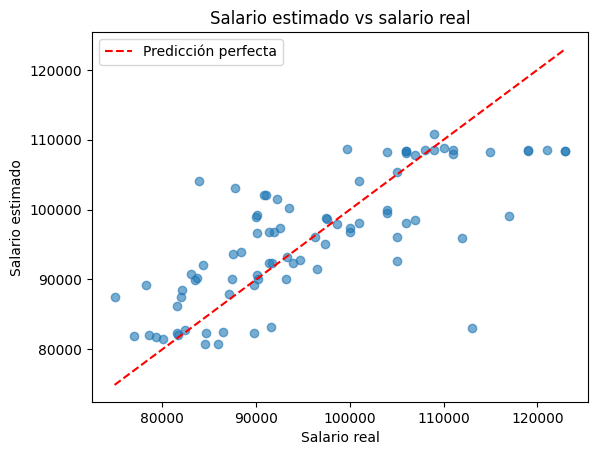

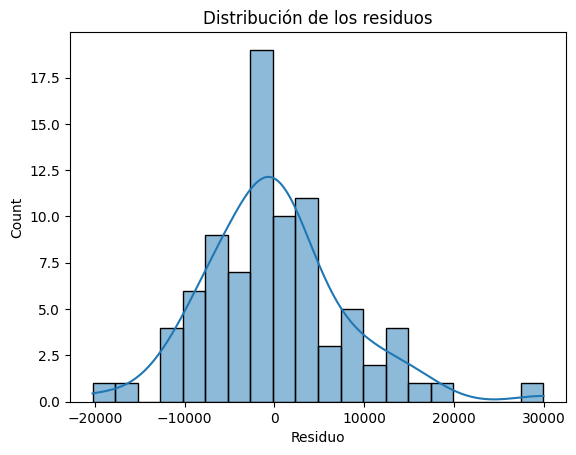

In [5]:
import matplotlib.pyplot as plt

y_real = df["salary"]
y_pred = modelo.fittedvalues

plt.scatter(y_real, y_pred, alpha=0.6)

# Línea de referencia: predicción perfecta (y = x)
minimo = min(y_real.min(), y_pred.min())
maximo = max(y_real.max(), y_pred.max())
plt.plot([minimo, maximo], [minimo, maximo], color="red", linestyle="--", label="Predicción perfecta")

plt.title("Salario estimado vs salario real")
plt.xlabel("Salario real")
plt.ylabel("Salario estimado")
plt.legend()
plt.show()

residuos = modelo.resid

sns.histplot(residuos, bins=20, kde=True)
plt.title("Distribución de los residuos")
plt.xlabel("Residuo")
plt.show()

 Crea una gráfica de los errores residuales. Discute lo que observas

 **Respuesta: El histograma de los residuos muestra que la mayoría de los errores se encuentran concentrados cerca de cero, lo cual es favorable porque indica que muchas predicciones no presentan desviaciones demasiado grandes respecto a los salarios reales. Sin embargo, la distribución no es completamente simétrica y presenta una cola hacia los valores positivos, así como algunos residuos extremos. Esto sugiere que existen observaciones cuyo salario real es considerablemente diferente del estimado por el modelo. **

# 5. Evalúa el modelo

- Calcula el MSE del modelo construido. Recuerda que usas el propio conjunto de datos (No hablamos nada de entrenamiento y test).
- Calcula el R² Score

Discute estos resultados obtenidos.

In [6]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 13. Calcular las métricas del modelo
mse = mean_squared_error(y_real, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y_real, y_pred)  # Error absoluto medio
r2 = r2_score(y_real, y_pred)  # Coeficiente de determinación R^2

# 14. Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")

Error Cuadrático Medio (MSE): 60480269.1466
Raíz del Error Cuadrático Medio (RMSE): 7776.9061
Error Absoluto Medio (MAE): 5697.5542
Coeficiente de Determinación (R²): 0.5705


**Discute estos resultados obtenidos: El modelo obtuvo un R² de 0.5705, lo que indica que el costo educativo y la ubicación geográfica explican aproximadamente el 57.05% de la variabilidad de los salarios.El MAE de 5,697.55 indica que las predicciones presentan un error absoluto promedio de aproximadamente 5,698 unidades, mientras que el RMSE de 7,776.91 refleja la presencia de errores más elevados. El MSE fue de 60,480,269.15. Lo anterior nos dice que el modelo tiene una capacidad explicativa moderada, por lo que creo que  existen otros factores que influyen en los salarios y que podrían ser considerados.**

# 6. Realiza un análisis de varianza con stastmodel

Consulta esto aquí https://www.statsmodels.org/dev/examples/notebooks/generated/variance_components.html

In [7]:
modelo_vc = smf.mixedlm("salary ~ cost", data=df, groups=df["location"]).fit()
print(modelo_vc.summary())

var_grupo = modelo_vc.cov_re.iloc[0, 0]
var_resid = modelo_vc.scale
icc = var_grupo / (var_grupo + var_resid)
print("ICC:", icc)

             Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  salary       
No. Observations:    85       Method:              REML         
No. Groups:          4        Scale:               64259988.9170
Min. group size:     19       Log-Likelihood:      -883.7724    
Max. group size:     25       Converged:           Yes          
Mean group size:     21.2                                       
----------------------------------------------------------------
             Coef.     Std.Err.   z    P>|z|   [0.025    0.975] 
----------------------------------------------------------------
Intercept    86475.116 4755.851 18.183 0.000 77153.819 95796.412
cost             0.063    0.017  3.619 0.000     0.029     0.097
Group Var 63375113.891 6902.606                                 

ICC: 0.496533574985214


Conclusión general: A partir del análisis realizado, se puede concluir que tanto el costo de la educación como la ubicación geográfica tienen una relación con los salarios. En general, las instituciones con mayores costos educativos tienden a presentar salarios más elevados, aunque esta relación también varía dependiendo de la región. El modelo de regresión lineal múltiple obtuvo un **R² de 57.05%, lo que significa que las variables consideradas explican poco más de la mitad de la variabilidad de los salarios. Esto indica que el modelo tiene una capacidad explicativa moderada, pero también que existen otros factores que podrían influir en los salarios y que no fueron incluidos en el análisis.

Por otra parte, el análisis de residuos permitió identificar diferencias entre los valores reales y los estimados, lo que demuestra que el modelo no consigue predecir todos los salarios con la misma precisión.
